In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits

# Load handwritten digits dataset
digits = load_digits()

print("Dataset loaded successfully!")
print("Total samples:", len(digits.data))
print("Total features:", digits.data.shape[1])
print("Available classes:", digits.target_names)

Dataset loaded successfully!
Total samples: 1797
Total features: 64
Available classes: [0 1 2 3 4 5 6 7 8 9]


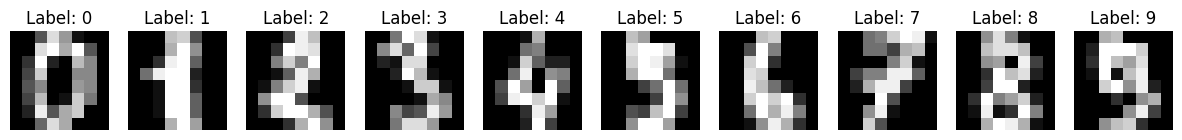

In [2]:
# Display first 10 handwritten digit images

fig, axes = plt.subplots(1, 10, figsize=(15, 3))

for i, ax in enumerate(axes):
    ax.imshow(digits.images[i], cmap='gray')
    ax.set_title(f"Label: {digits.target[i]}")
    ax.axis('off')

plt.show()

In [3]:
# Check dataset shape
print("Features shape:", digits.data.shape)
print("Target shape:", digits.target.shape)

# Display first five feature records
print("\nFirst five feature records:")
print(digits.data[:5])

# Display first five target labels
print("\nFirst five target labels:")
print(digits.target[:5])

Features shape: (1797, 64)
Target shape: (1797,)

First five feature records:
[[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
  15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
   0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
   0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]
 [ 0.  0.  0. 12. 13.  5.  0.  0.  0.  0.  0. 11. 16.  9.  0.  0.  0.  0.
   3. 15. 16.  6.  0.  0.  0.  7. 15. 16. 16.  2.  0.  0.  0.  0.  1. 16.
  16.  3.  0.  0.  0.  0.  1. 16. 16.  6.  0.  0.  0.  0.  1. 16. 16.  6.
   0.  0.  0.  0.  0. 11. 16. 10.  0.  0.]
 [ 0.  0.  0.  4. 15. 12.  0.  0.  0.  0.  3. 16. 15. 14.  0.  0.  0.  0.
   8. 13.  8. 16.  0.  0.  0.  0.  1.  6. 15. 11.  0.  0.  0.  1.  8. 13.
  15.  1.  0.  0.  0.  9. 16. 16.  5.  0.  0.  0.  0.  3. 13. 16. 16. 11.
   5.  0.  0.  0.  0.  3. 11. 16.  9.  0.]
 [ 0.  0.  7. 15. 13.  1.  0.  0.  0.  8. 13.  6. 15.  4.  0.  0.  0.  2.
   1. 13. 13.  0.  0.  0.  0.  0.  2. 15. 11.  1.  0.

In [4]:
# Separate features and target

X = digits.data
y = digits.target

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (1797, 64)
Target (y) shape: (1797,)


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1437
Testing samples: 360


In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# Create Dummy Classifier
dummy_model = DummyClassifier(strategy="most_frequent")

# Train the model
dummy_model.fit(X_train, y_train)

# Make predictions
dummy_predictions = dummy_model.predict(X_test)

# Calculate accuracy
dummy_accuracy = accuracy_score(y_test, dummy_predictions)

print("Dummy Classifier Accuracy:", dummy_accuracy)
print("Dummy Classifier Accuracy (%):", dummy_accuracy * 100)

Dummy Classifier Accuracy: 0.1
Dummy Classifier Accuracy (%): 10.0


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create machine learning pipeline
model_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=2000, random_state=42))
])

# Train the model
model_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [8]:
# Predict test data
y_pred = model_pipeline.predict(X_test)

# Calculate accuracy
model_accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", model_accuracy)
print("Logistic Regression Accuracy (%):", model_accuracy * 100)

Logistic Regression Accuracy: 0.9722222222222222
Logistic Regression Accuracy (%): 97.22222222222221


In [9]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate metrics for both models
results = pd.DataFrame({
    "Model": ["DummyClassifier", "Logistic Regression"],
    "Accuracy": [
        dummy_accuracy,
        model_accuracy
    ],
    "Precision": [
        precision_score(y_test, dummy_predictions, average="macro", zero_division=0),
        precision_score(y_test, y_pred, average="macro", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, dummy_predictions, average="macro", zero_division=0),
        recall_score(y_test, y_pred, average="macro", zero_division=0)
    ],
    "F1_Score": [
        f1_score(y_test, dummy_predictions, average="macro", zero_division=0),
        f1_score(y_test, y_pred, average="macro", zero_division=0)
    ]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1_Score
0      DummyClassifier  0.100000   0.010000  0.100000  0.018182
1  Logistic Regression  0.972222   0.972126  0.971905  0.971940


In [10]:
# Save evaluation metrics
results.to_csv("baseline_metrics.csv", index=False)

print("Metrics saved successfully!")

Metrics saved successfully!
